# Will It Rain Tomorrow in Australia?
## A leakage-safe, explainable machine-learning experiment

This notebook predicts whether it will rain tomorrow using the Australian Bureau of Meteorology–derived **Weather AUS** dataset published on Kaggle.

### Why this version is trustworthy

- Observations are split **chronologically**, so the model is always evaluated on later dates.
- Model and threshold choices use a **validation period only**.
- The final test period remains untouched until one final evaluation.
- Every model receives the same information and is compared against a no-skill baseline.
- We report class-sensitive metrics, calibration, error slices, and explainability—not accuracy alone.

> **Prediction framing:** Features are same-day weather observations available before the next-day outcome. This is a tabular prediction benchmark, not a replacement for a numerical weather-forecasting system.

## 1. Setup and reproducibility

The only nonstandard packages are `kagglehub` for the public dataset and `lightgbm` for the strongest candidate model. Random seeds and split fractions are fixed.

In [1]:
%pip install -q kagglehub lightgbm

import json
import os
import time
import warnings
from pathlib import Path

import joblib
import kagglehub
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from IPython.display import Markdown, display
from sklearn.calibration import CalibrationDisplay
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 42
TRAIN_FRACTION = 0.70
VALID_FRACTION = 0.15
TARGET = "RainTomorrow"
POSITIVE_LABEL = "Yes"

print(f"LightGBM {lgb.__version__} | pandas {pd.__version__}")

Note: you may need to restart the kernel to use updated packages.
LightGBM 4.6.0 | pandas 2.3.3


## 2. Load and audit the data

The expected grain is one weather station (`Location`) on one calendar day (`Date`). We remove rows without a known target because they cannot support supervised evaluation. Exact duplicate rows are also removed.

In [2]:
dataset_dir = Path(kagglehub.dataset_download("jsphyg/weather-dataset-rattle-package"))
csv_candidates = sorted(dataset_dir.glob("*.csv"))
assert csv_candidates, f"No CSV found in {dataset_dir}"

data_path = csv_candidates[0]
weather_raw = pd.read_csv(data_path)
weather_raw["Date"] = pd.to_datetime(weather_raw["Date"], errors="coerce")

rows_loaded = len(weather_raw)
exact_duplicates = int(weather_raw.duplicated().sum())
missing_target = int(weather_raw[TARGET].isna().sum())
invalid_dates = int(weather_raw["Date"].isna().sum())

weather = (
    weather_raw
    .drop_duplicates()
    .dropna(subset=["Date", TARGET])
    .sort_values(["Date", "Location"])
    .reset_index(drop=True)
)

assert set(weather[TARGET].unique()) == {"No", "Yes"}

audit = pd.Series({
    "Rows loaded": rows_loaded,
    "Columns": weather_raw.shape[1],
    "Exact duplicate rows": exact_duplicates,
    "Rows missing target": missing_target,
    "Rows with invalid date": invalid_dates,
    "Usable rows": len(weather),
    "First date": weather["Date"].min().date(),
    "Last date": weather["Date"].max().date(),
    "Locations": weather["Location"].nunique(),
    "Rain prevalence": f"{weather[TARGET].eq(POSITIVE_LABEL).mean():.1%}",
}, name="Dataset audit")
display(audit.to_frame())
display(weather.head(3))

,Dataset audit
Rows loaded,145460
Columns,23
Exact duplicate rows,0
Rows missing target,3267
Rows with invalid date,0
Usable rows,142193
First date,2007-11-01
Last date,2017-06-25
Locations,49
Rain prevalence,22.4%


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2007-11-01,Canberra,8.0,24.3,0.0,3.4,6.3,NW,30.0,SW,...,68.0,29.0,1019.7,1015.0,7.0,7.0,14.4,23.6,No,Yes
1,2007-11-02,Canberra,14.0,26.9,3.6,4.4,9.7,ENE,39.0,E,...,80.0,36.0,1012.4,1008.4,5.0,3.0,17.5,25.7,Yes,Yes
2,2007-11-03,Canberra,13.7,23.4,3.6,5.8,3.3,NW,85.0,N,...,82.0,69.0,1009.5,1007.2,8.0,7.0,15.4,20.2,Yes,Yes


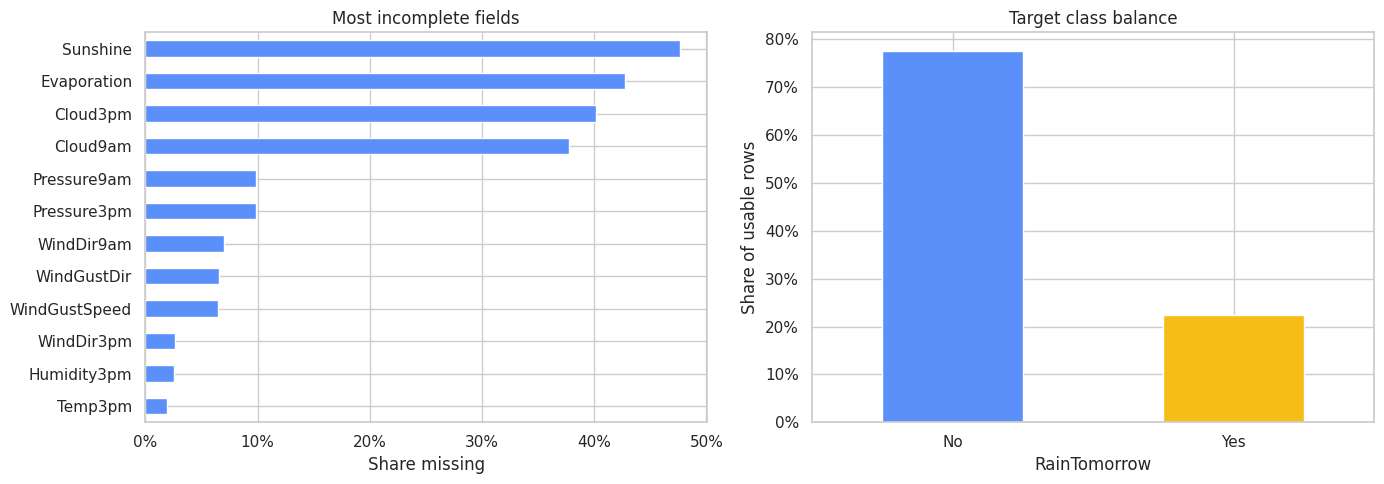

,Missing share
Sunshine,47.7%
Evaporation,42.8%
Cloud3pm,40.2%
Cloud9am,37.7%
Pressure9am,9.9%
Pressure3pm,9.8%
WindDir9am,7.0%
WindGustDir,6.6%
WindGustSpeed,6.5%
WindDir3pm,2.7%


In [3]:
missingness = (
    weather.isna().mean()
    .sort_values(ascending=False)
    .rename("Missing share")
    .to_frame()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
missingness.head(12).sort_values("Missing share").plot.barh(ax=axes[0], legend=False, color="#5B8FF9")
axes[0].set_title("Most incomplete fields")
axes[0].set_xlabel("Share missing")
axes[0].xaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")

weather[TARGET].value_counts(normalize=True).sort_index().plot.bar(ax=axes[1], color=["#5B8FF9", "#F6BD16"])
axes[1].set_title("Target class balance")
axes[1].set_ylabel("Share of usable rows")
axes[1].tick_params(axis="x", rotation=0)
axes[1].yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
plt.tight_layout()
plt.show()

display(missingness.head(12).style.format("{:.1%}"))

### Data-quality interpretation

Missing predictor values are expected in this observational dataset. All imputers are fitted on the training period only, preventing future information from leaking backward. We retain sparse predictors because missingness-aware pipelines can still extract useful signal from the observed values.

## 3. Leakage-safe features and chronological split

Calendar seasonality is encoded cyclically with sine/cosine terms. We keep `Location` as a categorical feature and avoid target encoding entirely. The raw date is used for splitting and auditing, then removed from model inputs.

The first 70% of unique dates form training, the next 15% validation, and the final 15% the untouched test period.

In [4]:
def add_calendar_features(frame):
    out = frame.copy()
    day_of_year = out["Date"].dt.dayofyear
    out["DayOfYear_sin"] = np.sin(2 * np.pi * day_of_year / 365.25)
    out["DayOfYear_cos"] = np.cos(2 * np.pi * day_of_year / 365.25)
    out["Year"] = out["Date"].dt.year
    return out


model_data = add_calendar_features(weather)
unique_dates = np.sort(model_data["Date"].unique())
train_end_idx = int(len(unique_dates) * TRAIN_FRACTION)
valid_end_idx = int(len(unique_dates) * (TRAIN_FRACTION + VALID_FRACTION))
train_end_date = pd.Timestamp(unique_dates[train_end_idx - 1])
valid_end_date = pd.Timestamp(unique_dates[valid_end_idx - 1])

train_df = model_data[model_data["Date"] <= train_end_date].copy()
valid_df = model_data[(model_data["Date"] > train_end_date) & (model_data["Date"] <= valid_end_date)].copy()
test_df = model_data[model_data["Date"] > valid_end_date].copy()

feature_columns = [c for c in model_data.columns if c not in [TARGET, "Date"]]
X_train, y_train = train_df[feature_columns], train_df[TARGET]
X_valid, y_valid = valid_df[feature_columns], valid_df[TARGET]
X_test, y_test = test_df[feature_columns], test_df[TARGET]

split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Rows": [len(train_df), len(valid_df), len(test_df)],
    "Start": [train_df.Date.min(), valid_df.Date.min(), test_df.Date.min()],
    "End": [train_df.Date.max(), valid_df.Date.max(), test_df.Date.max()],
    "Rain rate": [y_train.eq("Yes").mean(), y_valid.eq("Yes").mean(), y_test.eq("Yes").mean()],
})

assert train_df.Date.max() < valid_df.Date.min() < test_df.Date.min()
assert not (set(train_df.index) & set(valid_df.index) or set(train_df.index) & set(test_df.index))
display(split_summary.style.format({"Rain rate": "{:.1%}", "Start": "{:%Y-%m-%d}", "End": "{:%Y-%m-%d}"}))

,Split,Rows,Start,End,Rain rate
0,Train,93076,2007-11-01,2014-08-29,22.8%
1,Validation,24358,2014-08-30,2016-01-26,20.4%
2,Test,24759,2016-01-27,2017-06-25,22.9%


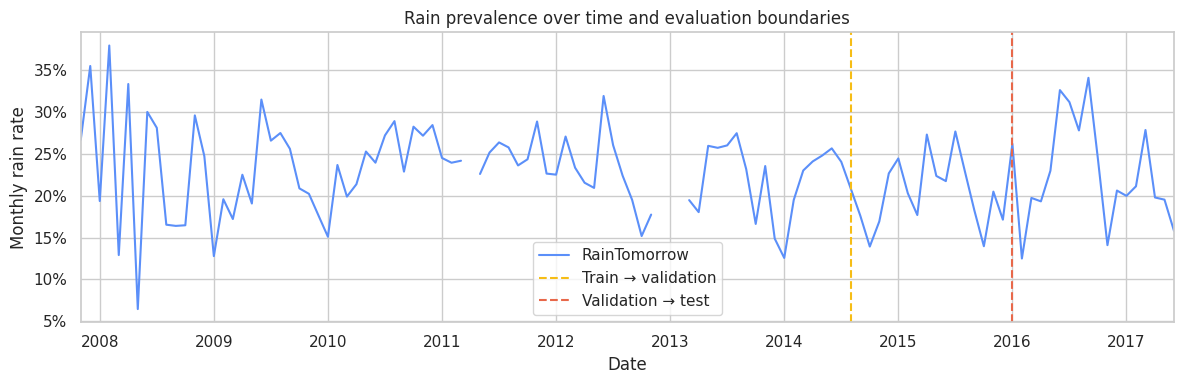

In [5]:
fig, ax = plt.subplots(figsize=(12, 4))
monthly_rate = (
    model_data.set_index("Date")[TARGET].eq("Yes")
    .resample("MS").mean()
)
monthly_rate.plot(ax=ax, color="#5B8FF9", linewidth=1.5)
ax.axvline(train_end_date, color="#F6BD16", linestyle="--", label="Train → validation")
ax.axvline(valid_end_date, color="#E8684A", linestyle="--", label="Validation → test")
ax.set(title="Rain prevalence over time and evaluation boundaries", ylabel="Monthly rain rate", xlabel="Date")
ax.yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Fair model comparison on validation data

We compare:

1. **No-skill baseline:** always predicts the majority class.
2. **Logistic regression:** transparent linear baseline with one-hot categoricals.
3. **LightGBM:** nonlinear boosted trees with regularization.

The primary selection metric is **PR-AUC (average precision)** because rain is the minority class and the metric evaluates probability ranking across useful thresholds.

In [6]:
numeric_features = X_train.select_dtypes(exclude="object").columns.tolist()
categorical_features = X_train.select_dtypes(include="object").columns.tolist()

linear_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_features),
])

tree_preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ordinal", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
    ]), categorical_features),
]).set_output(transform="pandas")

models = {
    "No-skill majority": DummyClassifier(strategy="prior"),
    "Logistic regression": Pipeline([
        ("prep", linear_preprocessor),
        ("model", LogisticRegression(max_iter=600, random_state=RANDOM_STATE)),
    ]),
    "LightGBM": Pipeline([
        ("prep", tree_preprocessor),
        ("model", lgb.LGBMClassifier(
            objective="binary",
            n_estimators=500,
            learning_rate=0.04,
            num_leaves=31,
            subsample=0.9,
            subsample_freq=1,
            colsample_bytree=0.9,
            reg_lambda=1.0,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbosity=-1,
        )),
    ]),
}


def positive_probability(model, X):
    positive_index = list(model.classes_).index(POSITIVE_LABEL)
    return model.predict_proba(X)[:, positive_index]


def metric_row(y_true, probabilities, threshold=0.5):
    y_binary = y_true.eq(POSITIVE_LABEL).astype(int).to_numpy()
    predictions = np.where(probabilities >= threshold, "Yes", "No")
    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Balanced accuracy": balanced_accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, pos_label="Yes", zero_division=0),
        "Recall": recall_score(y_true, predictions, pos_label="Yes", zero_division=0),
        "F1": f1_score(y_true, predictions, pos_label="Yes", zero_division=0),
        "ROC-AUC": roc_auc_score(y_binary, probabilities),
        "PR-AUC": average_precision_score(y_binary, probabilities),
        "Brier score": brier_score_loss(y_binary, probabilities),
    }


validation_rows = []
fit_seconds = {}
for name, model in models.items():
    started = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds[name] = time.perf_counter() - started
    valid_prob = positive_probability(model, X_valid)
    row = metric_row(y_valid, valid_prob)
    row.update({"Model": name, "Fit seconds": fit_seconds[name]})
    validation_rows.append(row)

validation_results = pd.DataFrame(validation_rows).set_index("Model").sort_values("PR-AUC", ascending=False)
display(validation_results.style.format("{:.3f}").highlight_max(subset=["PR-AUC", "ROC-AUC", "F1"], color="#d9ead3"))

,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier score,Fit seconds
Model,,,,,,,,,
LightGBM,0.859,0.714,0.744,0.470,0.576,0.882,0.704,0.101,4.400
Logistic regression,0.852,0.699,0.729,0.441,0.549,0.864,0.670,0.107,1.423
No-skill majority,0.796,0.500,0.000,0.000,0.000,0.500,0.204,0.163,0.069


## 5. Select the model and operating threshold

The best validation PR-AUC determines the model. Within that model, we choose the probability threshold that maximizes validation F1. This makes the precision/recall trade-off explicit while preserving the final test period for one honest evaluation.

**Selected model:** LightGBM  
**Selected threshold:** 0.254 (maximum validation F1)

,Precision,Recall,F1,Accuracy,PR-AUC
Default threshold (0.50),0.744,0.470,0.576,0.859,0.704
Validation-tuned threshold (0.254),0.577,0.708,0.636,0.835,0.704


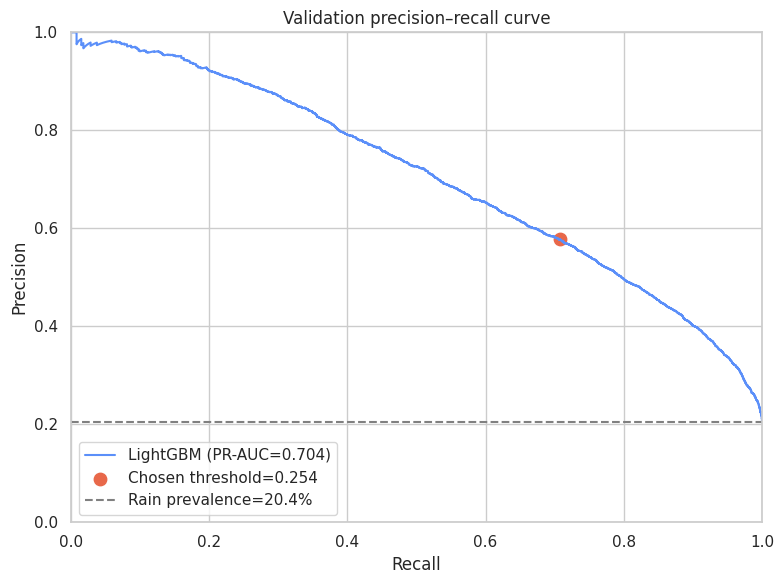

In [7]:
selected_model_name = validation_results.index[0]
selected_model = models[selected_model_name]
valid_prob = positive_probability(selected_model, X_valid)
valid_binary = y_valid.eq(POSITIVE_LABEL).astype(int).to_numpy()

precision_curve, recall_curve, thresholds = precision_recall_curve(valid_binary, valid_prob)
threshold_f1 = 2 * precision_curve[:-1] * recall_curve[:-1] / (precision_curve[:-1] + recall_curve[:-1] + 1e-12)
best_threshold_index = int(np.nanargmax(threshold_f1))
selected_threshold = float(thresholds[best_threshold_index])

default_valid = metric_row(y_valid, valid_prob, threshold=0.5)
tuned_valid = metric_row(y_valid, valid_prob, threshold=selected_threshold)
threshold_comparison = pd.DataFrame(
    [default_valid, tuned_valid],
    index=["Default threshold (0.50)", f"Validation-tuned threshold ({selected_threshold:.3f})"],
)

display(Markdown(f"**Selected model:** {selected_model_name}  \n**Selected threshold:** {selected_threshold:.3f} (maximum validation F1)"))
display(threshold_comparison[["Precision", "Recall", "F1", "Accuracy", "PR-AUC"]].style.format("{:.3f}"))

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(recall_curve, precision_curve, color="#5B8FF9", label=f"{selected_model_name} (PR-AUC={tuned_valid['PR-AUC']:.3f})")
ax.scatter(recall_curve[best_threshold_index], precision_curve[best_threshold_index], color="#E8684A", s=80,
           label=f"Chosen threshold={selected_threshold:.3f}")
ax.axhline(valid_binary.mean(), color="gray", linestyle="--", label=f"Rain prevalence={valid_binary.mean():.1%}")
ax.set(title="Validation precision–recall curve", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1))
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

## 6. One final evaluation on untouched future dates

From this point onward, the test set is used once to estimate future-period performance. No model or threshold changes are made after viewing these results.

,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier score
Validation,0.835,0.788,0.577,0.708,0.636,0.882,0.704,0.101
Untouched test,0.814,0.795,0.571,0.760,0.652,0.879,0.729,0.107


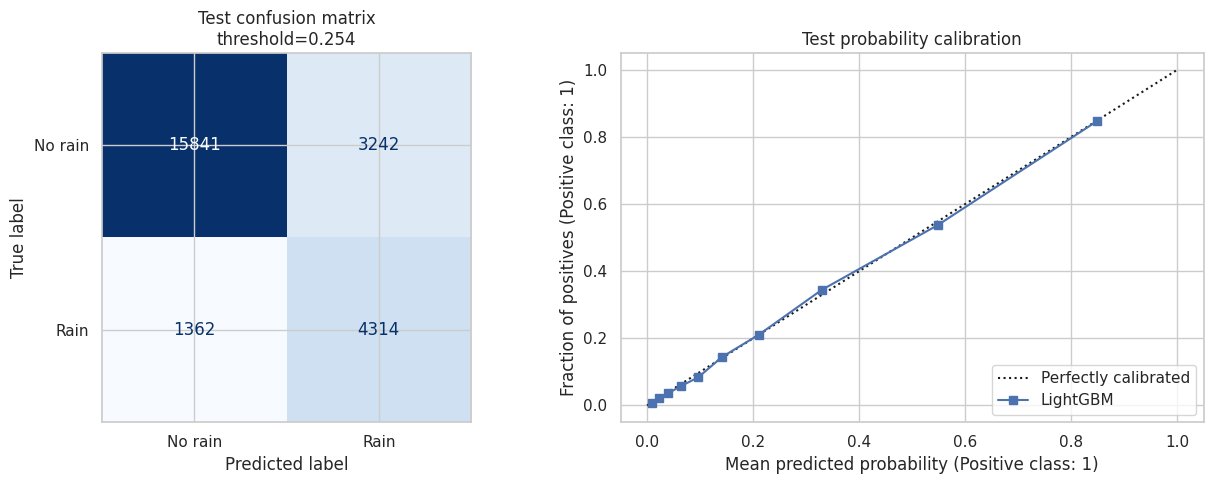

              precision    recall  f1-score   support

          No      0.921     0.830     0.873     19083
         Yes      0.571     0.760     0.652      5676

    accuracy                          0.814     24759
   macro avg      0.746     0.795     0.763     24759
weighted avg      0.841     0.814     0.822     24759



In [8]:
test_prob = positive_probability(selected_model, X_test)
test_metrics = metric_row(y_test, test_prob, threshold=selected_threshold)
test_pred = np.where(test_prob >= selected_threshold, "Yes", "No")

final_results = pd.DataFrame({
    "Validation": tuned_valid,
    "Untouched test": test_metrics,
}).T
display(final_results.style.format("{:.3f}"))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, labels=["No", "Yes"], display_labels=["No rain", "Rain"],
    cmap="Blues", colorbar=False, ax=axes[0]
)
axes[0].set_title(f"Test confusion matrix\nthreshold={selected_threshold:.3f}")

CalibrationDisplay.from_predictions(
    y_test.eq("Yes").astype(int), test_prob, n_bins=10, strategy="quantile",
    name=selected_model_name, ax=axes[1]
)
axes[1].set_title("Test probability calibration")
plt.tight_layout()
plt.show()

print(classification_report(y_test, test_pred, labels=["No", "Yes"], digits=3))

## 7. Explainability

Permutation importance measures the decrease in test PR-AUC when one feature is shuffled. It is model-agnostic and keeps the explanation at the original feature level. To keep runtime bounded, importance is estimated on a fixed 5,000-row test sample.

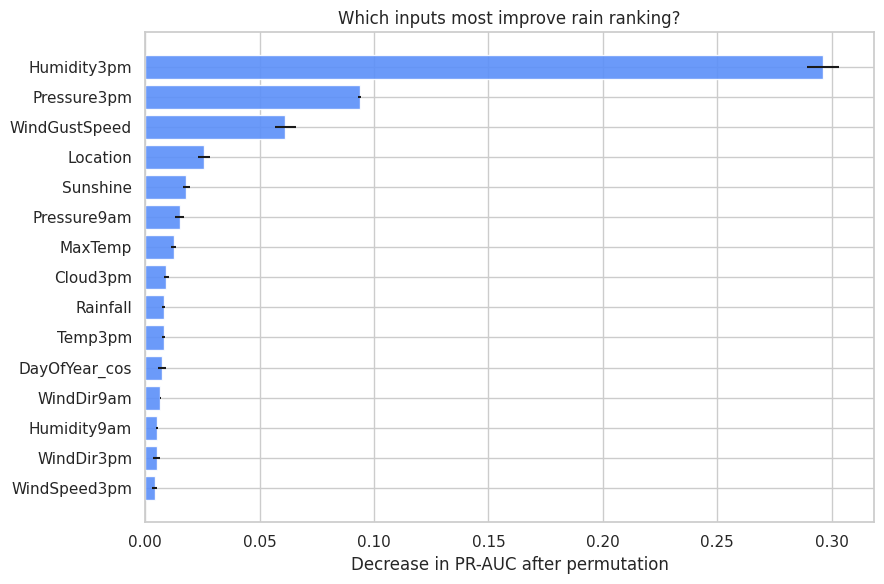

,Feature,Importance,Std
13,Humidity3pm,0.2964,0.0070
15,Pressure3pm,0.0936,0.0008
7,WindGustSpeed,0.0612,0.0048
0,Location,0.0257,0.0026
5,Sunshine,0.0180,0.0014
14,Pressure9am,0.0150,0.0020
2,MaxTemp,0.0123,0.0009
17,Cloud3pm,0.0093,0.0012
3,Rainfall,0.0080,0.0006
19,Temp3pm,0.0080,0.0006


In [9]:
importance_sample = X_test.sample(min(5000, len(X_test)), random_state=RANDOM_STATE)
importance_target = y_test.loc[importance_sample.index]
from sklearn.metrics import make_scorer

pr_auc_scorer = make_scorer(
    average_precision_score,
    response_method="predict_proba",
    pos_label="Yes",
)

importance_result = permutation_importance(
    selected_model,
    importance_sample,
    importance_target,
    scoring=pr_auc_scorer,
    n_repeats=3,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

importance = (
    pd.DataFrame({
        "Feature": feature_columns,
        "Importance": importance_result.importances_mean,
        "Std": importance_result.importances_std,
    })
    .sort_values("Importance", ascending=False)
    .head(15)
)

fig, ax = plt.subplots(figsize=(9, 6))
plot_data = importance.sort_values("Importance")
ax.barh(plot_data["Feature"], plot_data["Importance"], xerr=plot_data["Std"], color="#5B8FF9", alpha=0.9)
ax.set(title="Which inputs most improve rain ranking?", xlabel="Decrease in PR-AUC after permutation", ylabel="")
plt.tight_layout()
plt.show()
display(importance.style.format({"Importance": "{:.4f}", "Std": "{:.4f}"}))

## 8. Where does the model struggle?

Aggregate metrics can hide weak segments. We inspect test performance by season and by location, suppressing tiny groups. These slices are diagnostic only and do not drive further tuning.

In [10]:
error_frame = test_df[["Date", "Location", TARGET]].copy()
error_frame["Probability"] = test_prob
error_frame["Prediction"] = test_pred
error_frame["ActualRain"] = error_frame[TARGET].eq("Yes")
error_frame["Correct"] = error_frame["Prediction"].eq(error_frame[TARGET])

month = error_frame["Date"].dt.month
error_frame["Season"] = np.select(
    [month.isin([12, 1, 2]), month.isin([3, 4, 5]), month.isin([6, 7, 8])],
    ["Summer", "Autumn", "Winter"],
    default="Spring",
)


def slice_metrics(group):
    actual = group[TARGET]
    pred = group["Prediction"]
    return pd.Series({
        "Rows": len(group),
        "Rain cases": actual.eq("Yes").sum(),
        "Rain rate": actual.eq("Yes").mean(),
        "Precision": precision_score(actual, pred, pos_label="Yes", zero_division=0),
        "Recall": recall_score(actual, pred, pos_label="Yes", zero_division=0),
        "F1": f1_score(actual, pred, pos_label="Yes", zero_division=0),
    })


season_results = error_frame.groupby("Season", observed=True).apply(slice_metrics).sort_values("Recall")
location_results = error_frame.groupby("Location", observed=True).apply(slice_metrics)
location_results = location_results[location_results["Rain cases"] >= 50].sort_values("Recall")

display(Markdown("### Performance by season"))
display(season_results.style.format({"Rain rate": "{:.1%}", "Precision": "{:.3f}", "Recall": "{:.3f}", "F1": "{:.3f}"}))
display(Markdown("### Lowest-recall locations with at least 50 rainy test days"))
display(location_results.head(10).style.format({"Rain rate": "{:.1%}", "Precision": "{:.3f}", "Recall": "{:.3f}", "F1": "{:.3f}"}))

### Performance by season

,Rows,Rain cases,Rain rate,Precision,Recall,F1
Season,,,,,,
Summer,5859.000000,1155.000000,19.7%,0.537,0.705,0.610
Autumn,8837.000000,1904.000000,21.5%,0.561,0.738,0.638
Spring,4377.000000,1059.000000,24.2%,0.557,0.771,0.647
Winter,5686.000000,1558.000000,27.4%,0.617,0.820,0.705


### Lowest-recall locations with at least 50 rainy test days

,Rows,Rain cases,Rain rate,Precision,Recall,F1
Location,,,,,,
Newcastle,494.000000,116.000000,23.5%,0.422,0.328,0.369
Tuggeranong,510.000000,109.000000,21.4%,0.586,0.596,0.591
SalmonGums,513.000000,85.000000,16.6%,0.593,0.600,0.596
Richmond,513.000000,92.000000,17.9%,0.528,0.609,0.566
Penrith,502.000000,82.000000,16.3%,0.515,0.610,0.559
BadgerysCreek,498.000000,92.000000,18.5%,0.464,0.630,0.535
Canberra,514.000000,102.000000,19.8%,0.536,0.657,0.590
WaggaWagga,483.000000,102.000000,21.1%,0.673,0.667,0.670
Cobar,503.000000,77.000000,15.3%,0.570,0.688,0.624


## 9. Reproducible artifacts and final takeaway

The score table, threshold, test predictions, and trained pipeline are saved for inspection. The generated summary below is tied directly to the executed results, avoiding stale hard-coded claims.

In [11]:
artifacts_dir = Path("rain_experiment_artifacts")
artifacts_dir.mkdir(exist_ok=True)

validation_results.to_csv(artifacts_dir / "validation_model_comparison.csv")
final_results.to_csv(artifacts_dir / "final_metrics.csv")
importance.to_csv(artifacts_dir / "permutation_importance.csv", index=False)
error_frame[["Date", "Location", TARGET, "Probability", "Prediction"]].to_csv(
    artifacts_dir / "test_predictions.csv", index=False
)
joblib.dump(selected_model, artifacts_dir / "selected_model_pipeline.joblib")

run_metadata = {
    "data_source": "jsphyg/weather-dataset-rattle-package",
    "selected_model": selected_model_name,
    "selected_threshold": selected_threshold,
    "random_state": RANDOM_STATE,
    "train_end": str(train_end_date.date()),
    "validation_end": str(valid_end_date.date()),
    "test_end": str(test_df.Date.max().date()),
}
(artifacts_dir / "run_metadata.json").write_text(json.dumps(run_metadata, indent=2))

display(Markdown(f'''
## TL;DR

Using a chronological evaluation, **{selected_model_name}** was selected on validation PR-AUC and its decision threshold was tuned on validation data only. On the untouched future test period it achieved:

- **PR-AUC:** {test_metrics['PR-AUC']:.3f} (rain prevalence: {y_test.eq('Yes').mean():.3f})
- **ROC-AUC:** {test_metrics['ROC-AUC']:.3f}
- **Precision:** {test_metrics['Precision']:.3f}
- **Recall:** {test_metrics['Recall']:.3f}
- **F1:** {test_metrics['F1']:.3f}
- **Brier score:** {test_metrics['Brier score']:.3f} (lower is better)

### Interpretation

The model is useful as a **next-day rain-risk classifier**, but its probabilities and errors vary across time and location. The untouched test score—not the earlier random-split accuracy—is the defensible estimate to quote. For operational use, the threshold should be chosen from the real cost of missed rain versus false alarms, and the model should be monitored for geographic and seasonal drift.

### Limitations

- This observational benchmark does not include numerical forecast-model outputs, radar, or satellite data.
- Station coverage and missingness vary over time.
- Results describe the final historical test window and may not transfer unchanged to future climate or sensor regimes.
'''))

print(f"Saved artifacts to: {artifacts_dir.resolve()}")
print(sorted(p.name for p in artifacts_dir.iterdir()))


## TL;DR

Using a chronological evaluation, **LightGBM** was selected on validation PR-AUC and its decision threshold was tuned on validation data only. On the untouched future test period it achieved:

- **PR-AUC:** 0.729 (rain prevalence: 0.229)
- **ROC-AUC:** 0.879
- **Precision:** 0.571
- **Recall:** 0.760
- **F1:** 0.652
- **Brier score:** 0.107 (lower is better)

### Interpretation

The model is useful as a **next-day rain-risk classifier**, but its probabilities and errors vary across time and location. The untouched test score—not the earlier random-split accuracy—is the defensible estimate to quote. For operational use, the threshold should be chosen from the real cost of missed rain versus false alarms, and the model should be monitored for geographic and seasonal drift.

### Limitations

- This observational benchmark does not include numerical forecast-model outputs, radar, or satellite data.
- Station coverage and missingness vary over time.
- Results describe the final historical test window and may not transfer unchanged to future climate or sensor regimes.


Saved artifacts to: /kaggle/working/rain_experiment_artifacts
['final_metrics.csv', 'permutation_importance.csv', 'run_metadata.json', 'selected_model_pipeline.joblib', 'test_predictions.csv', 'validation_model_comparison.csv']
